# Assignment 10


In [1]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Core libraries and NLTK corpora loaded successfully!")


/home/gauransh-arora/Desktop/Cognitive_Computing_Assignments/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/gauransh-arora/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Core libraries and NLTK corpora loaded successfully!


## Question 1


In [2]:
corpus_data = [
    ("What are the primary warning signs and symptoms of a heart attack?", "symptoms_inquiry"),
    ("Why am I experiencing tightness, pressure, and squeezing in my chest?", "symptoms_inquiry"),
    ("Can pain radiating to the left arm, neck, and jaw indicate heart trouble?", "symptoms_inquiry"),
    ("What does cardiac angina feel like compared to indigestion?", "symptoms_inquiry"),
    ("Why do I have shortness of breath when lying flat or walking up stairs?", "symptoms_inquiry"),
    ("Are rapid heart palpitations and dizziness signs of an arrhythmia?", "symptoms_inquiry"),
    ("Can unexplained cold sweats, nausea, and lightheadedness be heart related?", "symptoms_inquiry"),
    ("What are atypical heart attack symptoms frequently experienced by women?", "symptoms_inquiry"),
    ("Is sudden swelling in my ankles, legs, and feet a sign of congestive heart failure?", "symptoms_inquiry"),
    ("Why do I feel persistent fatigue and an irregular fluttering pulse in my chest?", "symptoms_inquiry"),

    ("How can I naturally lower my LDL cholesterol levels through diet?", "lifestyle_prevention"),
    ("What aerobic cardiovascular exercises are safest for strengthening the heart muscle?", "lifestyle_prevention"),
    ("How does adopting the Mediterranean diet help prevent coronary artery disease?", "lifestyle_prevention"),
    ("What are the direct cardiovascular benefits of quitting smoking tobacco?", "lifestyle_prevention"),
    ("How does chronic psychological stress contribute to hypertension and heart disease?", "lifestyle_prevention"),
    ("How much dietary sodium should a heart patient consume each day?", "lifestyle_prevention"),
    ("Can regular brisk walking 30 minutes a day reduce my risk of a second cardiac event?", "lifestyle_prevention"),
    ("What foods should I strictly avoid to keep my coronary arteries free of plaque?", "lifestyle_prevention"),
    ("How does healthy weight loss and BMI control protect against cardiometabolic syndrome?", "lifestyle_prevention"),
    ("What role does adequate sleep of 7 to 8 hours play in cardiovascular recovery?", "lifestyle_prevention"),

    ("What is the therapeutic mechanism of beta-blockers like Metoprolol in heart disease?", "medication_guidance"),
    ("How do statin drugs such as Atorvastatin stabilize arterial plaque and lower cholesterol?", "medication_guidance"),
    ("Should I take a low-dose baby aspirin daily for cardiovascular prevention?", "medication_guidance"),
    ("What are common adverse side effects associated with ACE inhibitors like Lisinopril?", "medication_guidance"),
    ("How quickly does sublingual nitroglycerin relieve acute angina chest pain?", "medication_guidance"),
    ("Can I abruptly stop taking my prescribed blood pressure and heart medications?", "medication_guidance"),
    ("What should I do if I accidentally miss a morning dose of my blood thinner?", "medication_guidance"),
    ("How do calcium channel blockers like Amlodipine work to dilate coronary vessels?", "medication_guidance"),
    ("Are there dangerous interactions between grapefruit juice and statin medications?", "medication_guidance"),
    ("What is the function of diuretics like Furosemide in managing congestive heart failure?", "medication_guidance"),

    ("What is the clinical difference between an Electrocardiogram ECG and an Echocardiogram?", "diagnostic_tests"),
    ("What does an elevated Cardiac Troponin I or T blood test level indicate?", "diagnostic_tests"),
    ("How is a treadmill cardiac exercise stress test performed and what does it detect?", "diagnostic_tests"),
    ("What does a Coronary Artery Calcium CAC CT scan score tell me about my heart?", "diagnostic_tests"),
    ("What is Left Ventricular Ejection Fraction LVEF and what is a normal percentage?", "diagnostic_tests"),
    ("When should a patient undergo coronary angiography or cardiac catheterization?", "diagnostic_tests"),
    ("What does an elevated B-type Natriuretic Peptide BNP blood test result mean?", "diagnostic_tests"),
    ("How does a 24-hour Holter monitor help detect intermittent cardiac arrhythmias?", "diagnostic_tests"),
    ("Why did my cardiologist order a high-sensitivity C-reactive protein hs-CRP test?", "diagnostic_tests"),
    ("What is the purpose of a transesophageal echocardiogram TEE in evaluating heart valves?", "diagnostic_tests"),

    ("What is considered an optimal and normal blood pressure reading for an adult?", "blood_pressure_monitoring"),
    ("My home blood pressure monitor showed 145 over 95, is that considered Stage 2 hypertension?", "blood_pressure_monitoring"),
    ("What is the correct protocol and posture for measuring blood pressure at home?", "blood_pressure_monitoring"),
    ("What is isolated systolic hypertension and why does systolic pressure rise with age?", "blood_pressure_monitoring"),
    ("Why does my blood pressure spike higher in the doctor's office than at home white coat syndrome?", "blood_pressure_monitoring"),
    ("At what blood pressure threshold does a reading qualify as a hypertensive crisis emergency?", "blood_pressure_monitoring"),
    ("How often should a person diagnosed with high blood pressure check their vitals daily?", "blood_pressure_monitoring"),
    ("Can high blood pressure damage coronary arteries and lead to heart failure over time?", "blood_pressure_monitoring"),
    ("What does the bottom diastolic number in a blood pressure reading represent clinically?", "blood_pressure_monitoring"),
    ("Can drinking caffeine or exercising right before taking BP give an artificially high reading?", "blood_pressure_monitoring")
]

df_corpus = pd.DataFrame(corpus_data, columns=['query', 'intent'])
print(f"Total labelled corpus queries: {len(df_corpus)}")
print("\nIntent Distribution Breakdown:")
print(df_corpus['intent'].value_counts())
display(df_corpus.head(10))


Total labelled corpus queries: 50

Intent Distribution Breakdown:
intent
symptoms_inquiry             10
lifestyle_prevention         10
medication_guidance          10
diagnostic_tests             10
blood_pressure_monitoring    10
Name: count, dtype: int64


,query,intent
0,What are the primary warning signs and symptom...,symptoms_inquiry
1,"Why am I experiencing tightness, pressure, and...",symptoms_inquiry
2,"Can pain radiating to the left arm, neck, and ...",symptoms_inquiry
3,What does cardiac angina feel like compared to...,symptoms_inquiry
4,Why do I have shortness of breath when lying f...,symptoms_inquiry
5,Are rapid heart palpitations and dizziness sig...,symptoms_inquiry
6,"Can unexplained cold sweats, nausea, and light...",symptoms_inquiry
7,What are atypical heart attack symptoms freque...,symptoms_inquiry
8,"Is sudden swelling in my ankles, legs, and fee...",symptoms_inquiry
9,Why do I feel persistent fatigue and an irregu...,symptoms_inquiry


## Question 2


In [3]:
taxonomy_structure = {
    "1. Cardiovascular Pathologies": [
        "1.1 Ischemic Heart Disease (CAD, Angina Pectoris)",
        "1.2 Myocardial & Rhythm Disorders (Heart Failure, Arrhythmia)"
    ],
    "2. Diagnostic Screenings": [
        "2.1 Electrophysiology & Imaging (ECG, Echocardiogram, CT Angio)",
        "2.2 Biochemical Biomarkers (Troponin, BNP, Lipid Profile)"
    ],
    "3. Therapeutics & Pharmacology": [
        "3.1 Hemodynamic Modulators (Beta-Blockers, ACE Inhibitors)",
        "3.2 Plaque Stabilizers & Antithrombotics (Statins, Antiplatelets)"
    ],
    "4. Preventive Cardiology": [
        "4.1 Cardioprotective Nutrition (DASH Diet, Sodium Reduction)",
        "4.2 Physical Conditioning (Aerobic Training, Smoking Cessation)"
    ]
}

print("=" * 70)
print("HEART HEALTH HIERARCHICAL TAXONOMY CATALOG")
print("=" * 70)
for major, subs in taxonomy_structure.items():
    print(f"\n📂 {major.upper()}")
    for sub in subs:
        print(f"   └── 📄 {sub}")


HEART HEALTH HIERARCHICAL TAXONOMY CATALOG

📂 1. CARDIOVASCULAR PATHOLOGIES
   └── 📄 1.1 Ischemic Heart Disease (CAD, Angina Pectoris)
   └── 📄 1.2 Myocardial & Rhythm Disorders (Heart Failure, Arrhythmia)

📂 2. DIAGNOSTIC SCREENINGS
   └── 📄 2.1 Electrophysiology & Imaging (ECG, Echocardiogram, CT Angio)
   └── 📄 2.2 Biochemical Biomarkers (Troponin, BNP, Lipid Profile)

📂 3. THERAPEUTICS & PHARMACOLOGY
   └── 📄 3.1 Hemodynamic Modulators (Beta-Blockers, ACE Inhibitors)
   └── 📄 3.2 Plaque Stabilizers & Antithrombotics (Statins, Antiplatelets)

📂 4. PREVENTIVE CARDIOLOGY
   └── 📄 4.1 Cardioprotective Nutrition (DASH Diet, Sodium Reduction)
   └── 📄 4.2 Physical Conditioning (Aerobic Training, Smoking Cessation)


## Question 3


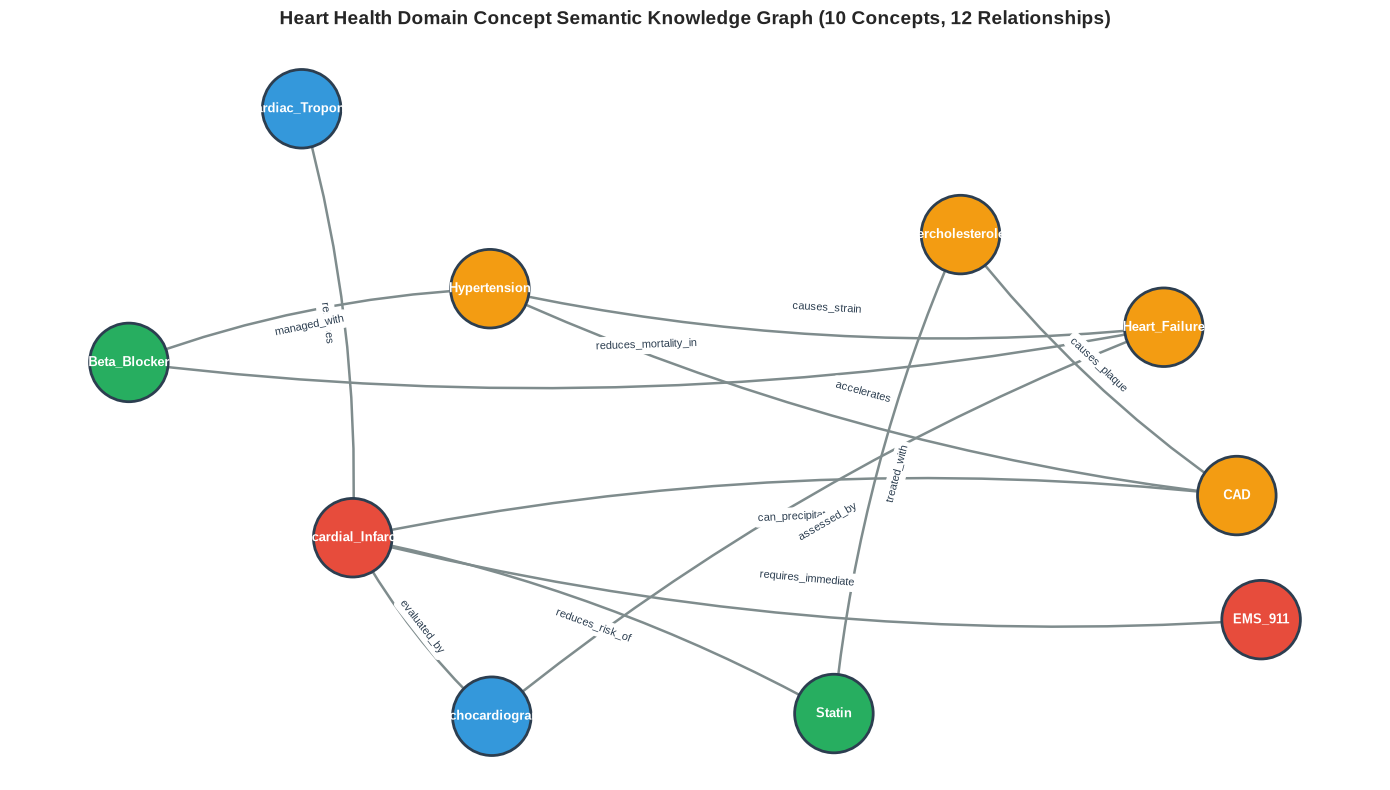

Total Graph Nodes (Domain Concepts): 10
Total Graph Directed Edges (Relationships): 12


In [4]:
G = nx.DiGraph()

relationships = [
    ("Hypercholesterolemia", "CAD", "causes_plaque"),
    ("CAD", "Myocardial_Infarction", "can_precipitate"),
    ("Hypertension", "CAD", "accelerates"),
    ("Hypertension", "Heart_Failure", "causes_strain"),
    ("Myocardial_Infarction", "Cardiac_Troponin", "releases"),
    ("Myocardial_Infarction", "EMS_911", "requires_immediate"),
    ("Myocardial_Infarction", "Echocardiogram", "evaluated_by"),
    ("Hypertension", "Beta_Blocker", "managed_with"),
    ("Hypercholesterolemia", "Statin", "treated_with"),
    ("Statin", "Myocardial_Infarction", "reduces_risk_of"),
    ("Heart_Failure", "Echocardiogram", "assessed_by"),
    ("Beta_Blocker", "Heart_Failure", "reduces_mortality_in")
]

for src, dst, rel in relationships:
    G.add_edge(src, dst, label=rel)

plt.figure(figsize=(14, 8))
pos = nx.spring_layout(G, seed=42, k=1.8)

node_colors = []
for node in G.nodes():
    if node in ["Myocardial_Infarction", "EMS_911"]:
        node_colors.append('#E74C3C')
    elif node in ["Beta_Blocker", "Statin"]:
        node_colors.append('#27AE60')
    elif node in ["Cardiac_Troponin", "Echocardiogram"]:
        node_colors.append('#3498DB')
    else:
        node_colors.append('#F39C12')

nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=node_colors, edgecolors='#2C3E50', linewidths=2)
nx.draw_networkx_edges(G, pos, edge_color='#7F8C8D', arrows=True, arrowsize=20, width=1.8, connectionstyle='arc3,rad=0.08')
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', font_color='white')

edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, font_color='#2C3E50')

plt.title("Heart Health Domain Concept Semantic Knowledge Graph (10 Concepts, 12 Relationships)", fontsize=14, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"Total Graph Nodes (Domain Concepts): {G.number_of_nodes()}")
print(f"Total Graph Directed Edges (Relationships): {G.number_of_edges()}")


## Question 4


In [5]:
lemmatizer = WordNetLemmatizer()
stop_words_set = set(stopwords.words('english'))

def preprocess_query(text):
    text_lower = text.lower()

    tokens = re.findall(r'\b[a-z0-9]+\b', text_lower)

    processed_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words_set and len(token) > 1
    ]

    return " ".join(processed_tokens)

sample_raw = "What are the common warning symptoms of acute heart attacks in elderly patients?"
sample_cleaned = preprocess_query(sample_raw)

print("Original Query :", sample_raw)
print("Processed Query:", sample_cleaned)

df_corpus['clean_query'] = df_corpus['query'].apply(preprocess_query)
display(df_corpus[['query', 'clean_query', 'intent']].head(5))


Original Query : What are the common warning symptoms of acute heart attacks in elderly patients?
Processed Query: common warning symptom acute heart attack elderly patient


,query,clean_query,intent
0,What are the primary warning signs and symptom...,primary warning sign symptom heart attack,symptoms_inquiry
1,"Why am I experiencing tightness, pressure, and...",experiencing tightness pressure squeezing chest,symptoms_inquiry
2,"Can pain radiating to the left arm, neck, and ...",pain radiating left arm neck jaw indicate hear...,symptoms_inquiry
3,What does cardiac angina feel like compared to...,cardiac angina feel like compared indigestion,symptoms_inquiry
4,Why do I have shortness of breath when lying f...,shortness breath lying flat walking stair,symptoms_inquiry


## Question 5


In [6]:
X = df_corpus['clean_query']
y = df_corpus['intent']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples : {X_test.shape[0]}")
print(f"Vocabulary Dimension: {len(tfidf_vectorizer.get_feature_names_out())} features")

models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=200, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM": LinearSVC(C=1.0, random_state=42)
}

print("\nModel Comparison via 4-Fold Cross Validation:")
print("-" * 50)
for name, clf in models.items():
    cv_scores = cross_val_score(clf, tfidf_vectorizer.transform(X), y, cv=4, scoring='accuracy')
    print(f"{name:<25}: CV Mean Accuracy = {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

primary_model = LogisticRegression(C=1.5, max_iter=200, random_state=42)
primary_model.fit(X_train_tfidf, y_train)
print("\nPrimary Classifier (Logistic Regression) successfully trained!")


Training Samples: 37
Testing Samples : 13
Vocabulary Dimension: 439 features

Model Comparison via 4-Fold Cross Validation:
--------------------------------------------------
Logistic Regression      : CV Mean Accuracy = 56.09% (+/- 5.88%)
Multinomial Naive Bayes  : CV Mean Accuracy = 61.86% (+/- 7.39%)
Linear SVM               : CV Mean Accuracy = 59.94% (+/- 5.67%)

Primary Classifier (Logistic Regression) successfully trained!


## Question 6


Test Set Accuracy: 53.85%
Macro F1-Score   : 54.67%

Detailed Clinical Intent Classification Report:
                           precision    recall  f1-score   support

blood_pressure_monitoring       1.00      1.00      1.00         3
         diagnostic_tests       1.00      0.50      0.67         2
     lifestyle_prevention       0.33      0.33      0.33         3
      medication_guidance       0.33      0.33      0.33         3
         symptoms_inquiry       0.33      0.50      0.40         2

                 accuracy                           0.54        13
                macro avg       0.60      0.53      0.55        13
             weighted avg       0.59      0.54      0.55        13



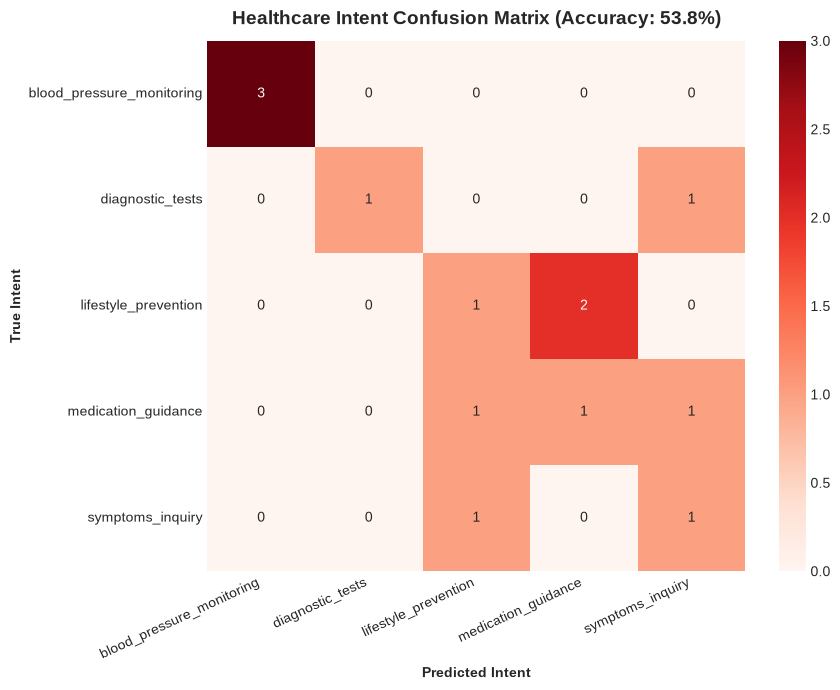

In [7]:
y_pred = primary_model.predict(X_test_tfidf)
test_accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Test Set Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-Score   : {macro_f1 * 100:.2f}%\n")
print("Detailed Clinical Intent Classification Report:")
print(classification_report(y_test, y_pred))

labels_order = sorted(list(df_corpus['intent'].unique()))
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels_order, yticklabels=labels_order)
plt.title(f"Healthcare Intent Confusion Matrix (Accuracy: {test_accuracy*100:.1f}%)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Predicted Intent", fontweight='bold')
plt.ylabel("True Intent", fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


## Question 7


In [8]:
cardiac_knowledge_base = {
    "symptoms_inquiry": {
        "title": "Cardiovascular Symptom Triage & Evaluation",
        "overview": "Cardiac symptoms originate from myocardial ischemia, electrical rhythm disturbance, or congestive volume overload.",
        "key_facts": [
            "Classic heart attack signs: Retrosternal squeezing/pressure, radiation to left arm, neck, jaw, or epigastrium.",
            "Atypical signs (frequent in women & diabetics): Unexplained dyspnea, extreme fatigue, nausea, cold sweats.",
            "Congestive signs: Bilateral lower extremity edema, orthopnea (difficulty breathing lying flat), paroxysmal nocturnal dyspnea.",
            "Palpitations: Fluttering, skipped beats, or tachycardia warrant ECG rhythm assessment."
        ],
        "clinical_guidance": "Any acute, unremitting central chest discomfort lasting over 5 minutes must be treated as a medical emergency.",
        "recommended_action": "Schedule an urgent cardiology consultation if symptoms are episodic; call EMS immediately if acute."
    },
    "lifestyle_prevention": {
        "title": "Preventive Cardiology & Lifestyle Modification",
        "overview": "Up to 80% of premature cardiovascular events are preventable via aggressive lifestyle and metabolic risk reduction.",
        "key_facts": [
            "Nutrition: Adopt the Mediterranean or DASH diet (rich in olive oil, legumes, leafy greens, wild fish, whole grains).",
            "Sodium Restriction: Limit daily sodium intake to under 1,500 mg - 2,000 mg to mitigate fluid retention and arterial stiffness.",
            "Physical Activity: Minimum 150 minutes of moderate aerobic exercise (brisk walking, swimming) per week.",
            "Smoking Cessation: Coronary disease risk decreases by 50% within 1 year of total tobacco cessation.",
            "Weight & Sleep: Target BMI between 18.5 and 24.9; maintain 7-8 hours of uninterrupted restorative sleep."
        ],
        "clinical_guidance": "Consistency in dietary patterns and progressive aerobic conditioning yields sustained reduction in atherosclerotic cardiovascular disease (ASCVD) risk.",
        "recommended_action": "Formulate a personalized cardioprotective exercise prescription in partnership with your physician."
    },
    "medication_guidance": {
        "title": "Cardiovascular Pharmacology & Therapeutics",
        "overview": "Prescribed cardiac drugs attenuate neurohormonal activation, reduce myocardial oxygen demand, stabilize plaque, and control blood pressure.",
        "key_facts": [
            "Beta-Blockers (e.g., Metoprolol, Carvedilol): Lower heart rate and myocardial contractility; NEVER stop abruptly due to rebound tachycardia.",
            "Statins (e.g., Atorvastatin, Rosuvastatin): Competitively inhibit HMG-CoA reductase, aggressively lower atherogenic LDL, and stabilize fibrous plaque caps.",
            "Antiplatelet Therapy (e.g., Aspirin, Clopidogrel): Inhibits platelet aggregation to prevent coronary stent thrombosis and secondary infarction.",
            "ACE Inhibitors / ARBs (e.g., Lisinopril, Losartan): Dilate peripheral arterioles, reduce afterload, and reverse ventricular remodeling in heart failure."
        ],
        "clinical_guidance": "Take medications exactly as scheduled every day. Never alter dosage or discontinue therapy without explicit cardiologist sign-off.",
        "recommended_action": "Review prescription compliance, electrolyte panels, and renal function at regular clinical intervals."
    },
    "diagnostic_tests": {
        "title": "Cardiac Diagnostic Modalities & Biomarkers",
        "overview": "Accurate cardiac diagnosis utilizes electrophysiological recordings, biochemical cardiac enzymes, and non-invasive acoustic/radiological imaging.",
        "key_facts": [
            "12-Lead ECG: Records electrical conduction vectors; identifies acute ST-elevation (STEMI), ischemia (T-wave inversions), or arrhythmias (Afib).",
            "High-Sensitivity Cardiac Troponin (hs-cTn): Gold-standard biomarker for cardiomyocyte necrosis; rises within 2-4 hours of myocardial infarction.",
            "Transthoracic Echocardiogram (Echo): Uses ultrasound to evaluate Left Ventricular Ejection Fraction (normal 55-70%), wall motion abnormalities, and valvular stenosis/regurgitation.",
            "Cardiac Stress Testing: Evaluates inducible myocardial ischemia under graded physical treadmill exertion or pharmacological stimulation.",
            "Coronary Artery Calcium (CAC) CT: Non-invasive quantification of calcified atherosclerotic coronary plaque (Agatston score)."
        ],
        "clinical_guidance": "Diagnostic findings must be interpreted holistically alongside clinical presentation, risk factor profiles, and hemodynamic vitals.",
        "recommended_action": "Consult your cardiologist to review specific imaging reports and establish optimal follow-up intervals."
    },
    "blood_pressure_monitoring": {
        "title": "Hypertension Surveillance & Hemodynamic Monitoring",
        "overview": "Hypertension ('the silent killer') exerts continuous barotrauma on vascular endothelial walls, accelerating coronary plaque rupture, stroke, and heart failure.",
        "key_facts": [
            "Normal Blood Pressure: Systolic < 120 mmHg AND Diastolic < 80 mmHg.",
            "Elevated BP: Systolic 120-129 mmHg AND Diastolic < 80 mmHg.",
            "Stage 1 Hypertension: Systolic 130-139 mmHg OR Diastolic 80-89 mmHg.",
            "Stage 2 Hypertension: Systolic ≥ 140 mmHg OR Diastolic ≥ 90 mmHg.",
            "Hypertensive Crisis: Systolic > 180 mmHg and/or Diastolic > 120 mmHg requires prompt or immediate emergency care."
        ],
        "clinical_guidance": "Measure BP twice daily (morning and evening) seated quietly for 5 minutes with arm supported at heart level. Avoid caffeine and nicotine 30 minutes prior.",
        "recommended_action": "Maintain an organized home blood pressure log to share with your healthcare provider during visits."
    }
}

print(f"Knowledge Base established with {len(cardiac_knowledge_base)} detailed clinical domains.")


Knowledge Base established with 5 detailed clinical domains.


## Question 8


In [9]:
class CardiacReasoningEngine:
    def __init__(self, confidence_threshold=0.38):
        self.conf_threshold = confidence_threshold

        self.emergency_patterns = [
            r'\bcrushing\s+chest\s+pain\b',
            r'\bchest\s+pain.*(?:arm|jaw|neck|back)\b',
            r'\b(?:radiating|spreading)\s+to\s+left\s+arm\b',
            r'\bpatient\s+collapsed\b',
            r'\bno\s+pulse\b',
            r'\bstopped\s+breathing\b',
            r'\bsudden\s+cardiac\s+arrest\b',
            r'\bunbearable\s+chest\s+pressure\b',
            r'\bsevere\s+chest\s+pain.*sweat\b',
            r'\bcall\s+911\b'
        ]

        self.unsupported_patterns = [
            r'\b(?:fracture|broken\s+bone|sprain|ankle|knee\s+arthritis|orthopedic)\b',
            r'\b(?:toothache|dental|cavity|teeth|dentist)\b',
            r'\b(?:skin\s+rash|eczema|acne|dermatology)\b',
            r'\b(?:capital\s+of|weather|bake\s+a\s+cake|recipe|stock\s+market)\b'
        ]

    def evaluate_rules(self, raw_query, predicted_intent, confidence):
        q = raw_query.lower()

        for pat in self.emergency_patterns:
            if re.search(pat, q):
                return {
                    "rule_triggered": "RULE_1_EMERGENCY_ESCALATION",
                    "action": "ESCALATE_IMMEDIATELY",
                    "response": (
                        "🚨🚨 [CRITICAL MEDICAL EMERGENCY DETECTED] 🚨🚨\n\n"
                        "Your query indicates acute, life-threatening cardiovascular symptoms that may represent an active Myocardial Infarction (Heart Attack) or Cardiac Arrest.\n\n"
                        "IMMEDIATE ACTIONS REQUIRED:\n"
                        "1. 📞 CALL 911 / 112 / LOCAL EMERGENCY SERVICES RIGHT NOW.\n"
                        "2. 🚫 DO NOT ATTEMPT TO DRIVE YOURSELF to the hospital.\n"
                        "3. 💊 Chew one adult 325 mg non-enteric coated aspirin (if not allergic and advised by emergency dispatch).\n"
                        "4. 🪑 Sit down, remain calm, loosen tight clothing, and unlock your front door for emergency paramedics.\n"
                        "5. If someone with you has collapsed with no pulse, begin hands-only CPR immediately."
                    )
                }

        bp_match = re.search(r'(\d{2,3})\s*(?:/|over)\s*(\d{2,3})', q)
        if bp_match:
            sys_val = int(bp_match.group(1))
            dia_val = int(bp_match.group(2))
            if sys_val >= 180 or dia_val >= 120:
                return {
                    "rule_triggered": "RULE_4_HYPERTENSIVE_CRISIS",
                    "action": "HYPERTENSIVE_CRISIS_ALERT",
                    "response": (
                        f"⚠️⚠️ [HYPERTENSIVE CRISIS WARNING: {sys_val}/{dia_val} mmHg] ⚠️⚠️\n\n"
                        "A blood pressure reading exceeding 180 mmHg systolic or 120 mmHg diastolic represents a Hypertensive Crisis.\n\n"
                        "• If you have ANY associated symptoms (chest pain, shortness of breath, blurry vision, severe headache, numbness): CALL 911 IMMEDIATELY.\n"
                        "• If you have NO other symptoms: Rest quietly for 5 minutes and re-test. If readings remain above 180/120, contact emergency medical care immediately."
                    )
                }

        if any(term in q for term in ['stop taking', 'quit cold turkey', 'abruptly stop', 'missed dose']):
            if any(med in q for med in ['beta blocker', 'metoprolol', 'blood pressure', 'statin', 'blood thinner']):
                return {
                    "rule_triggered": "RULE_5_MEDICATION_SAFETY",
                    "action": "MEDICATION_WARNING",
                    "response": (
                        "⚠️ [CRITICAL MEDICATION SAFETY WARNING]\n\n"
                        "NEVER abruptly discontinue cardiac medications (such as beta-blockers or antihypertensives) without direct physician supervision.\n"
                        "• Abrupt cessation of beta-blockers can cause dangerous rebound hypertension, severe angina, or trigger an acute cardiac event.\n"
                        "• If you missed a dose, take it as soon as remembered unless it is close to your next scheduled dose. Never take a double dose to compensate."
                    )
                }

        for pat in self.unsupported_patterns:
            if re.search(pat, q):
                return {
                    "rule_triggered": "RULE_3_UNSUPPORTED_QUERY",
                    "action": "REJECT_AND_REORIENT",
                    "response": (
                        "ℹ️ [UNSUPPORTED HEALTHCARE QUERY]\n\n"
                        "I am specialized strictly as a Cardiovascular Health Information Assistant.\n"
                        "Your question appears to relate to non-cardiac healthcare or general inquiries outside my clinical scope.\n\n"
                        "👉 I can assist you with:\n"
                        "  • Heart disease symptoms & warning signs\n"
                        "  • Cardioprotective lifestyle, diet & exercise\n"
                        "  • Cardiac medications (statins, beta-blockers, ACE inhibitors)\n"
                        "  • Diagnostic tests (ECG, Echocardiogram, Troponin, CAC)\n"
                        "  • Blood pressure monitoring & hypertension management."
                    )
                }

        if confidence < self.conf_threshold:
            return {
                "rule_triggered": "RULE_2_LOW_CONFIDENCE",
                "action": "REQUEST_CLARIFICATION",
                "response": (
                    f"❓ [UNCERTAIN QUERY / LOW CONFIDENCE ({confidence*100:.1f}%)]\n\n"
                    "I could not confidently determine the specific cardiovascular topic of your question.\n"
                    "Could you please rephrase or specify which area you would like information on?\n\n"
                    "Suggested topics:\n"
                    "1. 'What are the symptoms of a heart attack?'\n"
                    "2. 'How can I lower blood pressure and cholesterol naturally?'\n"
                    "3. 'What are the side effects of statin medications?'\n"
                    "4. 'What does an echocardiogram test for?'"
                )
            }

        return None


## Question 9


In [10]:
class HeartHealthCognitiveAssistant:
    def __init__(self, classifier, vectorizer, knowledge_base, reasoning_engine):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.kb = knowledge_base
        self.reasoning = reasoning_engine

    def process_query(self, user_query):
        cleaned_text = preprocess_query(user_query)

        X_vec = self.vectorizer.transform([cleaned_text])
        probabilities = self.classifier.predict_proba(X_vec)[0]
        max_idx = np.argmax(probabilities)

        predicted_intent = self.classifier.classes_[max_idx]
        confidence = probabilities[max_idx]

        rule_result = self.reasoning.evaluate_rules(user_query, predicted_intent, confidence)

        if rule_result is not None:
            return {
                "query": user_query,
                "clean_query": cleaned_text,
                "intent": predicted_intent,
                "confidence": confidence,
                "rule_triggered": rule_result["rule_triggered"],
                "response": rule_result["response"]
            }

        kb_entry = self.kb.get(predicted_intent, None)
        if kb_entry:
            formatted_response = (
                f"🩺 [{kb_entry['title'].upper()}]\n"
                f"Confidence Score: {confidence*100:.1f}% (Class: {predicted_intent})\n\n"
                f"📋 Clinical Overview:\n{kb_entry['overview']}\n\n"
                f"💡 Evidence-Based Key Facts:\n" + "\n".join([f"  • {fact}" for fact in kb_entry['key_facts']]) + "\n\n"
                f"🛡️ Clinical Guidance:\n{kb_entry['clinical_guidance']}\n\n"
                f"👉 Recommended Action:\n{kb_entry['recommended_action']}"
            )
        else:
            formatted_response = f"Information retrieved for intent category: {predicted_intent}."

        return {
            "query": user_query,
            "clean_query": cleaned_text,
            "intent": predicted_intent,
            "confidence": confidence,
            "rule_triggered": "NONE (Standard Knowledge Retrieval)",
            "response": formatted_response
        }

assistant = HeartHealthCognitiveAssistant(
    classifier=primary_model,
    vectorizer=tfidf_vectorizer,
    knowledge_base=cardiac_knowledge_base,
    reasoning_engine=CardiacReasoningEngine(confidence_threshold=0.38)
)

print("Heart Health Information Assistant successfully initialized and ready!")


Heart Health Information Assistant successfully initialized and ready!


## Question 10


In [11]:
test_scenarios = [
    {
        "category": "1. Defined Intent: symptoms_inquiry",
        "query": "What are the early warning signs of a myocardial infarction or heart attack?"
    },
    {
        "category": "1. Defined Intent: lifestyle_prevention",
        "query": "How can I reduce arterial plaque and bad LDL cholesterol with diet and exercise?"
    },
    {
        "category": "1. Defined Intent: medication_guidance",
        "query": "How do beta blocker medications help reduce strain on the heart?"
    },
    {
        "category": "1. Defined Intent: diagnostic_tests",
        "query": "What does a high cardiac troponin level mean on my blood test results?"
    },
    {
        "category": "1. Defined Intent: blood_pressure_monitoring",
        "query": "What is considered a normal systolic and diastolic blood pressure reading at home?"
    },

    {
        "category": "2. Differently Worded Query (Informal / Synonyms)",
        "query": "Can taking a brisk half-hour jog every morning keep my ticker in good shape?"
    },

    {
        "category": "3. Unsupported Healthcare Query (Orthopedic / Non-Cardiac)",
        "query": "What are the best physical therapy exercises for a fractured ankle and knee arthritis?"
    },

    {
        "category": "4. Low-Confidence Query (Vague / Ambiguous)",
        "query": "Feeling a bit strange and unusual today."
    },

    {
        "category": "5. Emergency-Related Query (Acute Chest Pain & Radiation)",
        "query": "Severe crushing chest pain radiating to left arm with cold sweat, please help!"
    },

    {
        "category": "Bonus: Hypertensive Crisis Triage",
        "query": "My blood pressure reading just flashed 195 over 125, is this dangerous?"
    }
]

print("=" * 85)
print("HEART HEALTH COGNITIVE ASSISTANT: MULTI-SCENARIO VERIFICATION SESSION")
print("=" * 85)

for i, tc in enumerate(test_scenarios, start=1):
    print(f"\n[TEST CASE {i}]: {tc['category']}")
    print(f"User Input: \"{tc['query']}\"")
    output = assistant.process_query(tc['query'])
    print(f"Rule Triggered     : {output['rule_triggered']}")
    print(f"Classified Intent  : {output['intent']} (Confidence: {output['confidence']*100:.1f}%)")
    print("-" * 50)
    print(output['response'])
    print("=" * 85)


HEART HEALTH COGNITIVE ASSISTANT: MULTI-SCENARIO VERIFICATION SESSION

[TEST CASE 1]: 1. Defined Intent: symptoms_inquiry
User Input: "What are the early warning signs of a myocardial infarction or heart attack?"
Rule Triggered     : NONE (Standard Knowledge Retrieval)
Classified Intent  : symptoms_inquiry (Confidence: 46.5%)
--------------------------------------------------
🩺 [CARDIOVASCULAR SYMPTOM TRIAGE & EVALUATION]
Confidence Score: 46.5% (Class: symptoms_inquiry)

📋 Clinical Overview:
Cardiac symptoms originate from myocardial ischemia, electrical rhythm disturbance, or congestive volume overload.

💡 Evidence-Based Key Facts:
  • Classic heart attack signs: Retrosternal squeezing/pressure, radiation to left arm, neck, jaw, or epigastrium.
  • Atypical signs (frequent in women & diabetics): Unexplained dyspnea, extreme fatigue, nausea, cold sweats.
  • Congestive signs: Bilateral lower extremity edema, orthopnea (difficulty breathing lying flat), paroxysmal nocturnal dyspnea.
  

In [12]:
def run_interactive_assistant():
    print("Heart Health Cognitive Assistant is active. (Enter queries or type 'exit' to quit)\n")
    sample_queries = [
        "Why is high diastolic pressure harmful to blood vessels?",
        "Can I quit taking my blood pressure medicine cold turkey?",
        "What is the difference between an ECG and an echocardiogram?"
    ]

    for sample in sample_queries:
        print(f"👉 Input: \"{sample}\"")
        resp = assistant.process_query(sample)
        print(resp['response'])
        print("\n" + "-" * 70 + "\n")

run_interactive_assistant()


Heart Health Cognitive Assistant is active. (Enter queries or type 'exit' to quit)

👉 Input: "Why is high diastolic pressure harmful to blood vessels?"
❓ [UNCERTAIN QUERY / LOW CONFIDENCE (29.8%)]

I could not confidently determine the specific cardiovascular topic of your question.
Could you please rephrase or specify which area you would like information on?

Suggested topics:
1. 'What are the symptoms of a heart attack?'
2. 'How can I lower blood pressure and cholesterol naturally?'
3. 'What are the side effects of statin medications?'
4. 'What does an echocardiogram test for?'

----------------------------------------------------------------------

👉 Input: "Can I quit taking my blood pressure medicine cold turkey?"
🩺 [HYPERTENSION SURVEILLANCE & HEMODYNAMIC MONITORING]
Confidence Score: 40.5% (Class: blood_pressure_monitoring)

📋 Clinical Overview:
Hypertension ('the silent killer') exerts continuous barotrauma on vascular endothelial walls, accelerating coronary plaque rupture, s